# Results and Conclusions

In [43]:
import pandas as pd
import matplotlib.pyplot as plt

### Popularity Baseline

In [44]:
df_popularity = pd.read_csv("../../results/candidate_generation_popularity_freshness_prior_hour_clicks_validation.csv")
pivoted_popularity = df_popularity.pivot(index="m", columns="metric", values="value")
pivoted_popularity


metric,catalogue_coverage,cold_article_recall,hit_rate,long_tail_recall,novelty_bits,personalisation,recall_impression_mean,recall_pooled
m,,,,,,,,
50,0.006879,0.0,0.687990,0.000000,11.138587,0.743603,0.609252,0.564980
100,0.012180,0.0,0.780799,0.000000,11.957905,0.706341,0.710469,0.677530
200,0.021309,0.0,0.865482,0.000000,12.856903,0.666242,0.816560,0.796126
250,0.024780,0.0,0.888629,0.169258,13.161621,0.651927,0.847158,0.830633
300,0.029177,0.0,0.903807,0.282778,13.410145,0.641047,0.867393,0.853777
350,0.032437,0.0,0.916709,0.377276,13.618038,0.624940,0.884224,0.873043
400,0.036308,0.0,0.924836,0.441808,13.784918,0.621071,0.895631,0.886199
450,0.040957,0.0,0.931824,0.492432,13.924614,0.626403,0.905196,0.896520
500,0.046405,0.0,0.937484,0.535999,14.046683,0.626914,0.912945,0.905402


### Collaborative Models

In [45]:
df_collaborative = pd.read_csv("../../results/candidate_generation_comparison_validation.csv")

M = 500
COLLABORATIVE_MODELS = ['popularity_freshness_prior_hour_clicks',
                        'cf_item_item', 
                        'gmf_bpr', 
                        'ncf_bpr', 
                        'ncf_features_early_bpr', 
                        'ncf_features_late_bpr'
                        ]

df_collaborative = df_collaborative[df_collaborative['m'] == M]
df_collaborative = df_collaborative[df_collaborative['model'].isin(COLLABORATIVE_MODELS)]
pivoted_collaborative = df_collaborative.pivot(index="model", columns="metric", values="value")
pivoted_collaborative

metric,catalogue_coverage,cold_article_recall,hit_rate,long_tail_recall,novelty_bits,personalisation,recall_impression_mean,recall_pooled
model,,,,,,,,
cf_item_item,0.646893,0.0,0.111055,0.065760,15.578570,0.617898,0.083102,0.078856
gmf_bpr,0.153246,0.0,0.098027,0.061260,15.598260,0.914610,0.065392,0.069807
ncf_bpr,0.020994,0.0,0.151278,0.048067,15.591338,0.015349,0.108013,0.107671
ncf_features_early_bpr,0.059847,0.0,0.141317,0.043976,15.602218,0.014690,0.100611,0.100332
ncf_features_late_bpr,0.060099,0.0,0.145206,0.044181,15.606754,0.026522,0.104513,0.103188
popularity_freshness_prior_hour_clicks,0.046405,0.0,0.937484,0.535999,14.046683,0.626914,0.912945,0.905402


At M=500, none of the collaborative models comes close to the popularity baseline on accuracy. The best of them, `ncf_bpr`, reaches only **0.131 pooled recall** and a **0.180 hit rate** — roughly one-seventh and one-fifth of the popularity baseline's **0.905** and **0.937**. The gap widens further for `cf_item_item` (**0.022** recall) and `gmf_bpr` (**0.070**), which suggests the implicit interaction signal is extremely sparse and that popularity/freshness dominates what users actually click in this news setting.

The trade-off flips on the diversity side. Every collaborative model records **zero cold-article recall**, and their long-tail recall is low (0.028–0.062 vs 0.536 for popularity). `cf_item_item` and `gmf_bpr` do post very high personalisation (~0.91) and catalogue coverage (0.76 and 0.15), but this is largely an artefact of spreading low-confidence recommendations across a wide item set rather than surfacing genuinely relevant ones.

Within the family, the NCF variants are the strongest on accuracy, but `ncf_bpr` and the feature-augmented NCF models collapse personalisation to ~0.01–0.03 — they recommend almost the same block of items to every user, the opposite failure mode from `cf_item_item`. Adding content features does not help either: `ncf_features_early_bpr` and `ncf_features_late_bpr` actually *lose* recall versus plain `ncf_bpr` (0.100 / 0.103 vs 0.131), so side-information adds noise rather than signal at this scale. Net: no collaborative model is a credible sole retriever, and the whole family is outclassed by both the popularity baseline and the content-based models below.

### Content Models

In [46]:
df_content = pd.read_csv("../../results/candidate_generation_comparison_validation.csv")

M = 500
CONTENT_MODELS = ['popularity_freshness_prior_hour_clicks',
                  'content_entity', 
                  'content_text', 
                  'content_text_entity', 
                  'content_two_tower_mlp_bpr', 
                  'niche_two_tower'
                  ]
df_content = df_content[df_content['m'] == M]
df_content = df_content[df_content['model'].isin(CONTENT_MODELS)]
pivoted_content = df_content.pivot(index="model", columns="metric", values="value")
pivoted_content

metric,catalogue_coverage,cold_article_recall,hit_rate,long_tail_recall,novelty_bits,personalisation,recall_impression_mean,recall_pooled
model,,,,,,,,
content_entity,0.784425,0.035088,0.032950,0.033442,15.709916,0.915453,0.023225,0.022518
content_text,0.984055,0.020468,0.030673,0.028840,15.708259,0.929910,0.020565,0.020996
content_text_entity,0.941857,0.046784,0.043132,0.039681,15.708171,0.925434,0.030331,0.029732
content_two_tower_mlp_bpr,0.611616,0.052632,0.126771,0.061874,15.671233,0.928502,0.090281,0.092096
niche_two_tower,0.844903,0.307018,0.042088,0.144815,15.708518,0.938725,0.027073,0.029524
popularity_freshness_prior_hour_clicks,0.046405,0.000000,0.937484,0.535999,14.046683,0.626914,0.912945,0.905402


At M=500 the content models also trail the popularity baseline on accuracy — every model sits below **0.13 pooled recall** versus **0.905** for popularity — but they open a completely different operating point. Catalogue coverage is dramatically higher (0.61–0.98 vs 0.046) and cold-article recall is finally non-zero (0.02–0.31), which the popularity baseline cannot achieve at all.

`niche_two_tower` is the clear standout. It posts **0.307 cold-article recall** (roughly 6–15x every other content model), the **highest long-tail recall in the content family (0.145)**, and the highest personalisation (**0.939**), while keeping catalogue coverage at a healthy **0.845**. Crucially it does this without collapsing the other metrics: its pooled recall (0.030) is comparable to `content_text_entity` (0.030) and `content_entity` (0.023), so the niche specialisation is close to a free lunch on this evaluation.

`content_text` maximises raw coverage (**0.984**) with high personalisation (0.930) but has the weakest cold recall and long-tail reach of the family — broad but not targeted. `content_two_tower_mlp_bpr` is the best content model on pure accuracy (**0.092** recall, **0.127** hit rate) but it has the lowest catalogue coverage of the content models and mid-pack cold recall. `niche_two_tower` therefore offers the best balance: it is the only content model that materially moves cold and long-tail reach without giving up the rest.

Taken together, no single retriever wins on every axis. The popularity baseline maximises accuracy but reaches <5% of the catalogue and surfaces zero cold items; `niche_two_tower` maximises novelty and cold reach but is far weaker on accuracy. That is precisely the case for **dual-channel retrieval**: union a high-precision popularity channel with a high-recall niche channel so the reranker sees both popular and long-tail candidates.

## Finding the Optimal M

Candidate generation feeds directly into the reranker, so M controls a precision/recall trade-off. Retrieve too few candidates and relevant articles are lost before the reranker can ever see them; retrieve too many and the reranker is flooded with irrelevant items while latency and compute climb. We therefore sweep M for both channels and look for the point where each metric's marginal gain flattens — the elbow of the curve.

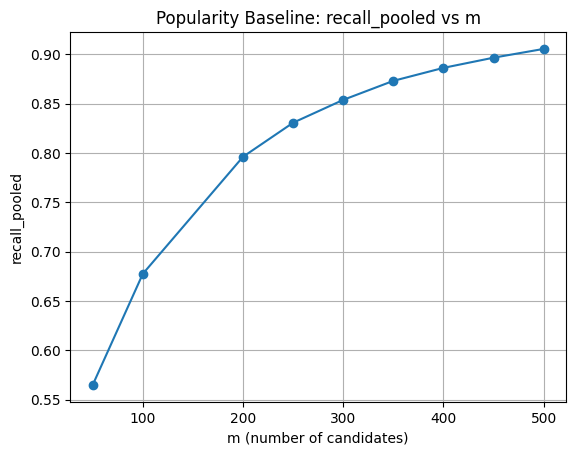

In [47]:
pivoted_popularity["recall_pooled"].plot(
    kind="line",
    marker="o",
    xlabel="m (number of candidates)",
    ylabel="recall_pooled",
    title="Popularity Baseline: recall_pooled vs m",
    grid=True,
)
plt.show()


`recall_pooled` rises steeply up to ~200 candidates, then visibly flattens: the gain from 200 → 250 is ~0.034, from 250 → 300 ~0.023, and from 300 → 500 only ~0.052 despite nearly doubling the candidate count. The first 200 candidates already recover ~0.796 pooled recall — about **88% of the 0.905 ceiling at M=500** — so ~200 is the elbow of the curve. Beyond it, each additional candidate buys progressively less recall.

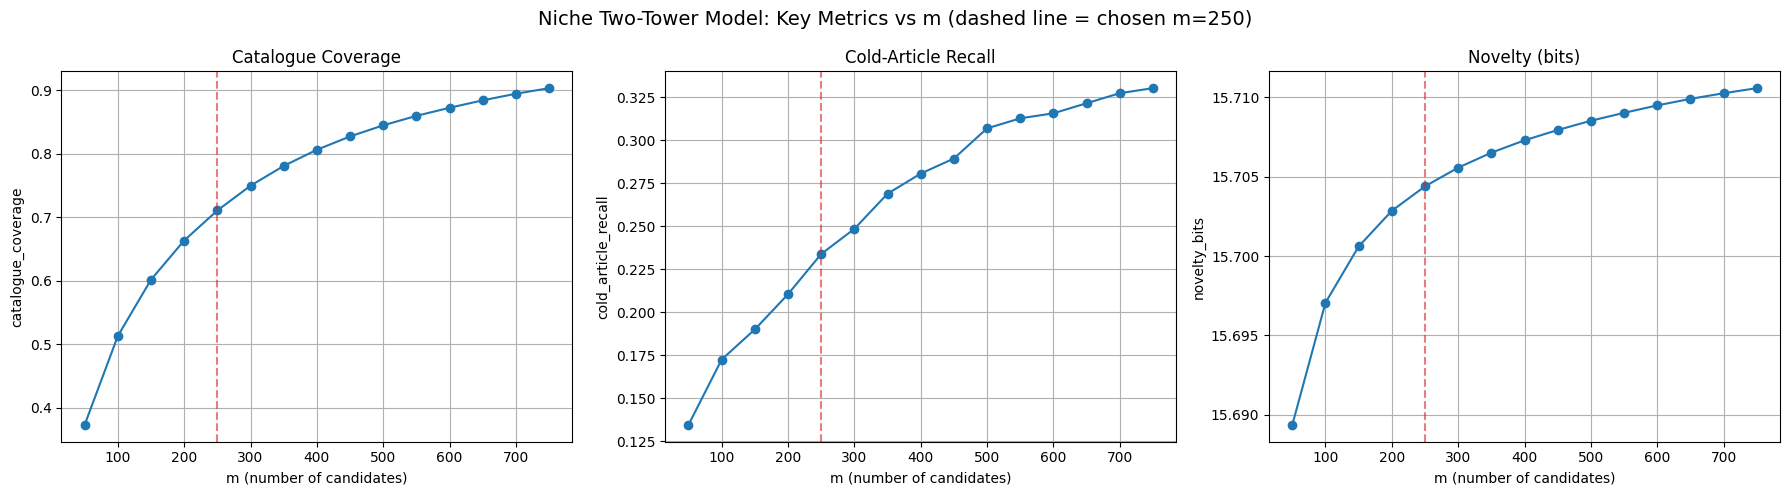

In [48]:
df_niche = pd.read_csv("../../results/candidate_generation_niche_two_tower_validation.csv")
pivoted_niche = df_niche.pivot(index="m", columns="metric", values="value")

metrics = ["catalogue_coverage", "cold_article_recall", "novelty_bits"]
titles = ["Catalogue Coverage", "Cold-Article Recall", "Novelty (bits)"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)

for ax, metric, title in zip(axes, metrics, titles):
    ax.plot(pivoted_niche.index, pivoted_niche[metric], marker="o", color="tab:blue")
    ax.axvline(250, color="tab:red", linestyle="--", alpha=0.6)
    ax.set_title(title)
    ax.set_xlabel("m (number of candidates)")
    ax.set_ylabel(metric)
    ax.grid(True)

fig.suptitle("Niche Two-Tower Model: Key Metrics vs m (dashed line = chosen m=250)", fontsize=14)
fig.tight_layout()
plt.show()

The three niche metrics tell a consistent story. `catalogue_coverage` grows almost linearly early but flattens after ~300 (0.71 at 250 → 0.84 at 500, a 0.13 gain over double the candidates). `cold_article_recall` rises fastest between 50 and 250 (0.135 → 0.234, +0.10) and then only adds ~0.07 more through 500. `novelty_bits` is effectively saturated by 250 (15.704 vs 15.709 at 500 — a negligible 0.005).

Combining both sweeps, the optimal split is **200 candidates from the popularity channel and 250 from the niche channel, for 450 candidates in total**. This keeps the popularity channel at its accuracy knee while giving the niche channel enough budget to capture the bulk of its cold/long-tail benefit without paying for saturated novelty.

## Combined Model Evaluation

In [49]:
df_combined = pd.read_csv("../../results/candidate_generation_comparison_validation.csv")

COMBINED_MODELS = [
    'baseline_content_popularity_combined',
    'popular_niche_200_250'
]

df_combined = df_combined[df_combined['model'].isin(COMBINED_MODELS)]
pivoted_combined = df_combined.pivot(index="model", columns="metric", values="value")
pivoted_combined

metric,catalogue_coverage,cold_article_recall,hit_rate,long_tail_recall,novelty_bits,personalisation,recall_impression_mean,recall_pooled
model,,,,,,,,
baseline_content_popularity_combined,0.874479,0.023392,0.860960,0.027818,14.453052,0.844149,0.811657,0.793019
popular_niche_200_250,0.712945,0.233918,0.873166,0.104418,14.444393,0.844188,0.826144,0.808636


The two combined retrievers are nearly indistinguishable on the headline accuracy metrics. `popular_niche_200_250` edges out `baseline_content_popularity_combined` on hit rate (**0.873 vs 0.861**), pooled recall (**0.809 vs 0.793**) and mean impression recall (**0.826 vs 0.812**), while novelty and personalisation are essentially identical (~14.44 and ~0.844).

The real separation is in reach. Moving to the popularity + niche combination:

- **Cold-article recall jumps ~10x**, from 0.023 to **0.234** — the niche channel is doing exactly the job it was added for.
- **Long-tail recall roughly quadruples**, from 0.028 to **0.104**.
- **Catalogue coverage falls ~18%**, from 0.874 to **0.713** — the only metric that regresses, and a deliberate consequence of concentrating the niche budget on distinctive items instead of spreading uniformly.

That coverage drop looks like a cost, but it is a *routing* effect rather than a loss of diversity: the niche channel still reaches 71% of the catalogue with a quarter of the budget, and the cold/long-tail recall gains are exactly the metrics a pure popularity system structurally cannot move. Since cold and long-tail articles are the ones most at risk of never being surfaced, and the accuracy metrics do not regress, the trained dual-channel model is the better candidate generator overall.

One caveat is worth stating explicitly: the combined model's pooled recall (0.81) is below the standalone popularity baseline at M=500 (0.91), because it spends 250 of its 450 slots on a niche channel with a low hit rate.